# VALORA AI — EDA & Machine Learning Modeling
**Project:** Apartment asking-price estimation in Montenegro  
**Goal:** Explore the dataset, clean records, train and evaluate regression models on **real apartment listings**.  
**Important:** The file includes 1,986 real listings and 2,000 simulated records. We exclude simulated records from training and evaluation in this baseline. Asking prices are not confirmed transaction prices. The 6-month forecast is a separate future task requiring historical data.

## 1. Load and inspect the dataset

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files

In [3]:
# Upload the dataset
uploaded = files.upload()

Saving Valora_AI_Dataset.csv to Valora_AI_Dataset (1).csv


In [4]:
# Read the dataset
filename = next(iter(uploaded))
df = pd.read_csv(filename)
df.shape

(3986, 19)

This shows how many rows and columns are in the dataset. Each row is one property record.

In [5]:
# Check the first 5 rows
df.head()

,listing_id,izvor,tip,cijena_eur,povrsina_m2,cijena_po_m2,sobe,kupatila,lokacija,grad,naslov,url,opis,provjera,data_origin,simulated_condition,simulated_year_built,simulated_floor,simulated_land_area_m2
0,2778761,Realitica,kuća,650000.0,250.0,2600.00,NaN,NaN,"Bar, Bar,",NaN,"kuću 3 sobe, 250 m2, €650.000 Bar, Bar,",https://www.realitica.com/hr/listing/2778761,NaN,OK,REAL,NaN,NaN,NaN,NaN
1,2961851,Realitica,kuća,520000.0,95.0,5473.68,NaN,NaN,"Baošići,",NaN,"kuću 3 sobe, 95 m2, €520.000 Baošići,",https://www.realitica.com/hr/listing/2961851,NaN,OK,REAL,NaN,NaN,NaN,NaN
2,3000522,Realitica,kuća,580000.0,314.0,1847.13,NaN,NaN,"Bijela,",NaN,"kuću 8 sobe, 314 m2, €580.000 Bijela,",https://www.realitica.com/hr/listing/3000522,NaN,OK,REAL,NaN,NaN,NaN,NaN
3,3000970,Realitica,kuća,580000.0,285.0,2035.09,NaN,NaN,"Đenovići,",NaN,"kuću 285 m2, €580.000 Đenovići,",https://www.realitica.com/hr/listing/3000970,NaN,OK,REAL,NaN,NaN,NaN,NaN
4,3001059,Realitica,kuća,320000.0,149.0,2147.65,NaN,NaN,"Podi,",NaN,"kuću 3 sobe, 149 m2, €320.000 Podi,",https://www.realitica.com/hr/listing/3001059,NaN,OK,REAL,NaN,NaN,NaN,NaN


Here I can see the first five properties and the information available for each one.

In [6]:
# Check the columns and data types
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3986 entries, 0 to 3985
Data columns (total 19 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   listing_id              3986 non-null   object 
 1   izvor                   3986 non-null   object 
 2   tip                     3984 non-null   object 
 3   cijena_eur              3986 non-null   float64
 4   povrsina_m2             3986 non-null   float64
 5   cijena_po_m2            3986 non-null   float64
 6   sobe                    3454 non-null   float64
 7   kupatila                386 non-null    float64
 8   lokacija                3986 non-null   object 
 9   grad                    3898 non-null   object 
 10  naslov                  3986 non-null   object 
 11  url                     1986 non-null   object 
 12  opis                    549 non-null    object 
 13  provjera                3986 non-null   object 
 14  data_origin             3986 non-null   

This shows the column names, data types and how many values are filled in.

In [7]:
# Check for missing values
df.isnull().sum()

,0
listing_id,0
izvor,0
tip,2
cijena_eur,0
povrsina_m2,0
cijena_po_m2,0
sobe,532
kupatila,3600
lokacija,0
grad,88


This table shows missing values in each column. I will check the important columns before cleaning the data.

In [8]:
# Check the summary statistics
df.describe()

,cijena_eur,povrsina_m2,cijena_po_m2,sobe,kupatila,simulated_year_built,simulated_floor,simulated_land_area_m2
count,3.986000e+03,3986.000000,3.986000e+03,3454.000000,386.000000,2000.000000,2000.000000,1000.000000
mean,2.366658e+05,117.355521,4.299608e+03,2.814708,1.316062,1996.921500,3.097000,823.213000
std,3.324074e+05,83.402864,6.713776e+04,1.544533,0.570806,17.313411,2.190888,408.121105
min,1.200000e+03,1.000000,5.130000e+00,0.000000,1.000000,1965.000000,0.000000,100.000000
25%,1.050000e+05,58.000000,9.745200e+02,2.000000,1.000000,1982.000000,1.000000,471.250000
50%,1.575000e+05,92.000000,1.852940e+03,3.000000,1.000000,1998.000000,3.000000,842.000000
75%,2.500000e+05,149.000000,2.997767e+03,4.000000,2.000000,2012.000000,4.000000,1185.250000
max,5.900000e+06,882.000000,3.000000e+06,20.000000,5.000000,2026.000000,8.000000,1499.000000


This table gives a quick summary of the numbers. Mean is the average, 50% is the median, and min and max show the smallest and largest values. Very high or low values might need checking.

In [9]:
# Check for duplicate rows
df.duplicated().sum()

np.int64(0)

This tells me how many rows are exactly the same. The same property can still appear more than once with slightly different details.

## 2. Initial data inspection

In [10]:
print('Columns:', df.columns.tolist())
print('Data origins:')
print(df['data_origin'].value_counts(dropna=False))
print('Property types:')
print(df['tip'].value_counts(dropna=False))
print('Missing values:')
print(df.isna().sum().sort_values(ascending=False))
display(df.describe(include='all').T)


Columns: ['listing_id', 'izvor', 'tip', 'cijena_eur', 'povrsina_m2', 'cijena_po_m2', 'sobe', 'kupatila', 'lokacija', 'grad', 'naslov', 'url', 'opis', 'provjera', 'data_origin', 'simulated_condition', 'simulated_year_built', 'simulated_floor', 'simulated_land_area_m2']
Data origins:
data_origin
SIMULATED    2000
REAL         1986
Name: count, dtype: int64
Property types:
tip
stan                 1967
kuća                 1408
Stan                  506
Kuća                   28
nepoznato              17
nejasno                14
ostalo/nepoznato       12
kuća (provjeriti)      12
Kuća/Vila               8
Nepoznato               6
NaN                     2
vila                    2
kuca                    2
Kuca                    2
Name: count, dtype: int64
Missing values:
kupatila                  3600
opis                      3437
simulated_land_area_m2    2986
url                       2000
simulated_condition       1986
simulated_floor           1986
simulated_year_built      1986


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
listing_id,3986,3986,SIM-H1000,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
izvor,3986,4,SIMULATED,2000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tip,3984,13,stan,1967,NaN,NaN,NaN,NaN,NaN,NaN,NaN
cijena_eur,3986.0,NaN,NaN,NaN,236665.840692,332407.38901,1200.0,105000.0,157500.0,250000.0,5900000.0
povrsina_m2,3986.0,NaN,NaN,NaN,117.355521,83.402864,1.0,58.0,92.0,149.0,882.0
cijena_po_m2,3986.0,NaN,NaN,NaN,4299.608287,67137.758036,5.13,974.52,1852.94,2997.7675,3000000.0
sobe,3454.0,NaN,NaN,NaN,2.814708,1.544533,0.0,2.0,3.0,4.0,20.0
kupatila,386.0,NaN,NaN,NaN,1.316062,0.570806,1.0,1.0,1.0,2.0,5.0
lokacija,3986,286,"Budva,",133,NaN,NaN,NaN,NaN,NaN,NaN,NaN
grad,3898,200,Podgorica,601,NaN,NaN,NaN,NaN,NaN,NaN,NaN


These tables show the types of properties, where the data came from, missing values and a general summary of all columns.

## 3. Data cleaning and selecting REAL apartments
Normalize apartment type spelling, exclude simulated records, and filter invalid or implausible values. Price thresholds are modeling choices, not statements about the market.

In [11]:
work = df.copy()
work['tip_clean'] = work['tip'].astype('string').str.strip().str.lower()
work['data_origin'] = work['data_origin'].astype('string').str.strip().str.upper()
work['cijena_eur'] = pd.to_numeric(work['cijena_eur'], errors='coerce')
work['povrsina_m2'] = pd.to_numeric(work['povrsina_m2'], errors='coerce')
work['sobe'] = pd.to_numeric(work['sobe'], errors='coerce')

real = work[(work['data_origin'] == 'REAL') & (work['tip_clean'] == 'stan')].copy()
print('Real apartment rows before cleaning:', len(real))
real = real.drop_duplicates(subset=['izvor', 'listing_id'])
real = real[(real['cijena_eur'].between(10000, 2000000)) & (real['povrsina_m2'].between(15, 350))].copy()
real['price_per_m2'] = real['cijena_eur'] / real['povrsina_m2']
real = real[real['price_per_m2'].between(300, 15000)].copy()
print('Real apartment rows after cleaning:', len(real))
print('Missing city:', real['grad'].isna().sum())
display(real[['grad','lokacija','povrsina_m2','sobe','cijena_eur','price_per_m2']].head())

Real apartment rows before cleaning: 1473
Real apartment rows after cleaning: 1432
Missing city: 3


,grad,lokacija,povrsina_m2,sobe,cijena_eur,price_per_m2
95,stan 1 sobe,"Đenovići,",59.0,1.0,154000.0,2610.169492
96,stan 5 sobe,"Meljine,",230.0,5.0,1520000.0,6608.695652
97,Kotor,"Kotor, Kotor,",58.0,1.0,320000.0,5517.241379
98,stan 2 sobe,"Baošići,",93.0,2.0,220000.0,2365.591398
99,stan 3 sobe,"Herceg Novi,",178.0,3.0,550000.0,3089.887640


This table shows a few apartments after cleaning. I kept real apartment listings and removed some records with unrealistic prices or sizes. I can also see the price per square meter.

## 4. EDA — prices, apartment size, and location

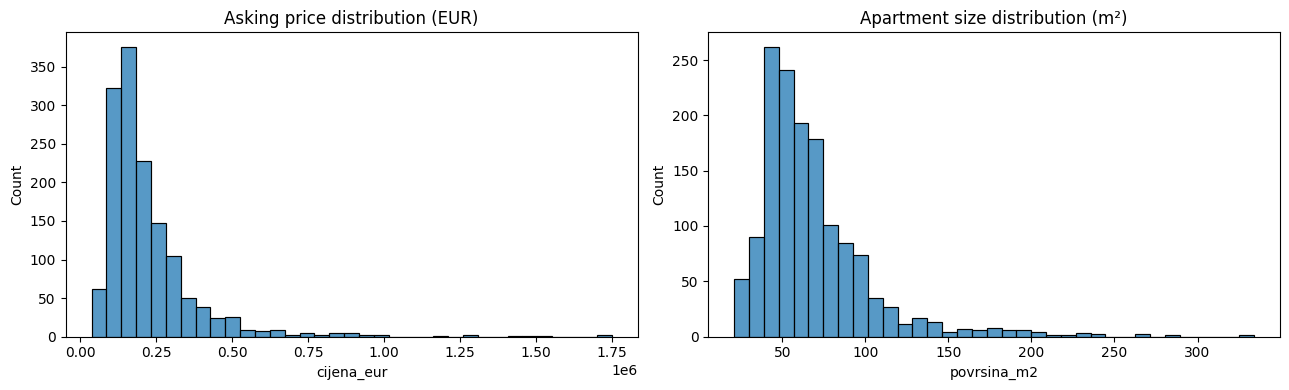

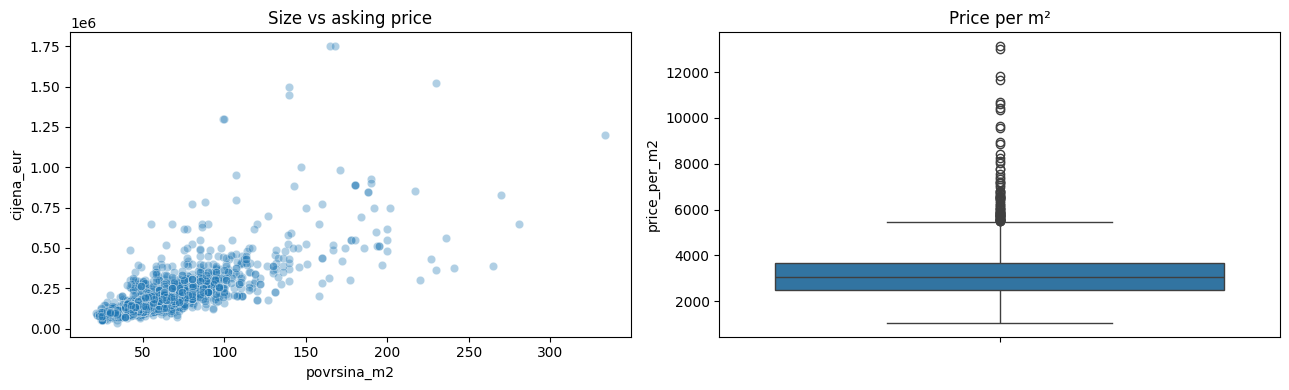

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(real['cijena_eur'], bins=35, ax=axes[0]); axes[0].set_title('Asking price distribution (EUR)')
sns.histplot(real['povrsina_m2'], bins=35, ax=axes[1]); axes[1].set_title('Apartment size distribution (m²)')
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.scatterplot(data=real, x='povrsina_m2', y='cijena_eur', alpha=.35, ax=axes[0])
axes[0].set_title('Size vs asking price')
sns.boxplot(data=real, y='price_per_m2', ax=axes[1]); axes[1].set_title('Price per m²')
plt.tight_layout(); plt.show()

The first charts show how prices and apartment sizes are distributed. The scatter plot compares size and price. The box plot helps me spot unusual prices per square meter.

Top city values (check data quality):


,count
grad,
Podgorica,494
stan 1 sobe,200
stan 2 sobe,177
Kolašin,55
stan 3 sobe,55
Ulcinj,49
Tivat,45
Cetinje,26
Centar,25


City coverage:


,count
city_model,
Podgorica,501
Unknown,297
Budva,196
Bar,83
Tivat,76
Kotor,67
Kolašin,59
Ulcinj,56
Cetinje,33


,listings,median_eur_m2
city_model,,
Tivat,76,4000.000000
Kotor,67,3783.783784
Budva,196,3500.000000
Unknown,297,3333.333333
Herceg Novi,19,3071.428571
Bar,83,2948.717949
Žabljak,16,2854.551920
Podgorica,501,2833.333333
Kolašin,59,2500.000000


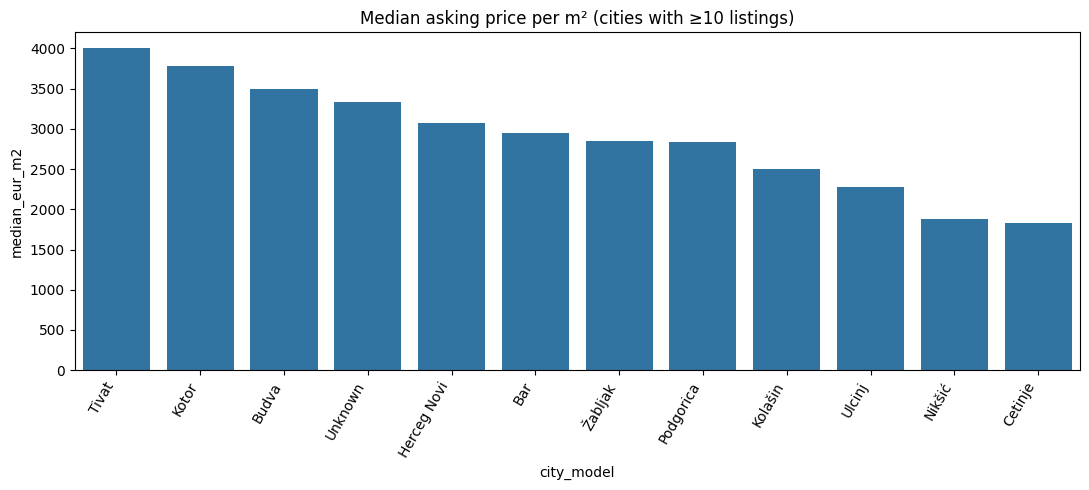

In [13]:
print('Top city values (check data quality):')
display(real['grad'].value_counts(dropna=False).head(15))
valid_cities = ['Podgorica','Budva','Bar','Kotor','Tivat','Herceg Novi','Ulcinj','Nikšić','Niksic','Cetinje','Kolašin','Kolasin','Žabljak','Zabljak','Bijelo Polje','Berane','Danilovgrad','Pljevlja','Plav','Rožaje','Rozaje','Mojkovac','Petnjica','Tuzi','Zeta','Andrijevica','Šavnik','Savnik','Plužine','Pluzine','Gusinje']
real['city_model'] = real['grad'].where(real['grad'].isin(valid_cities))
# Fill city only when it appears explicitly in the location text.
for city in valid_cities:
    mask = real['city_model'].isna() & real['lokacija'].fillna('').str.contains(city, case=False, regex=False)
    real.loc[mask, 'city_model'] = city
real['city_model'] = real['city_model'].fillna('Unknown')
print('City coverage:')
display(real['city_model'].value_counts().head(15))

city_stats = real.groupby('city_model').agg(listings=('cijena_eur','size'), median_eur_m2=('price_per_m2','median')).query('listings >= 10').sort_values('median_eur_m2', ascending=False)
display(city_stats)
plt.figure(figsize=(11,5)); sns.barplot(x=city_stats.index, y=city_stats['median_eur_m2']); plt.xticks(rotation=60, ha='right'); plt.title('Median asking price per m² (cities with ≥10 listings)'); plt.tight_layout(); plt.show()

The first tables show how many apartments we have in each city. The next table compares the median price per square meter, using cities with at least 10 listings. The bar chart makes these differences easier to see.

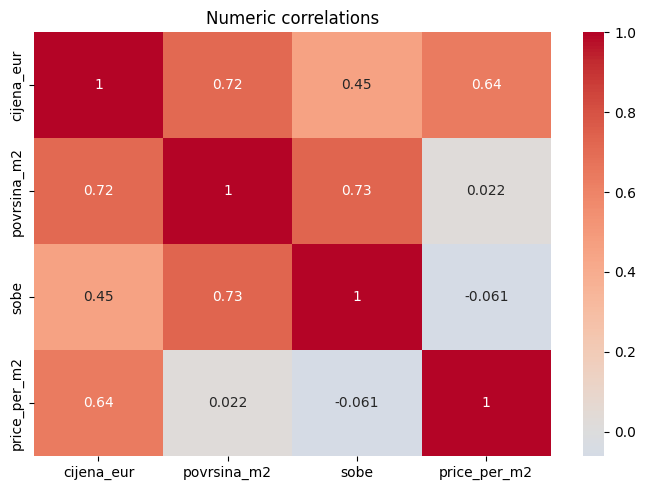

In [14]:
numeric_cols = ['cijena_eur', 'povrsina_m2', 'sobe', 'price_per_m2']
plt.figure(figsize=(7,5)); sns.heatmap(real[numeric_cols].corr(), annot=True, cmap='coolwarm', center=0); plt.title('Numeric correlations'); plt.tight_layout(); plt.show()

This chart shows correlations between the numeric columns. Values close to 1 mean a positive relationship, values close to -1 mean a negative relationship, and values close to 0 mean a weak linear relationship.

## 5. Feature engineering and train/test split
We predict **asking price in EUR** using apartment size, bedrooms, and city. `price_per_m2` is NOT used as a feature because it is calculated from the target price (data leakage). The test set contains only real listings.

In [15]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

features = ['povrsina_m2', 'sobe', 'city_model']
X = real[features].copy()
y = real['cijena_eur'].copy()
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print('Train:', len(X_train), 'Test:', len(X_test))

num_features = ['povrsina_m2','sobe']
cat_features = ['city_model']
preprocess = ColumnTransformer([
    ('num', Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())]), num_features),
    ('cat', Pipeline([('imputer', SimpleImputer(strategy='most_frequent')), ('onehot', OneHotEncoder(handle_unknown='ignore'))]), cat_features)
])

Train: 1145 Test: 287


I split the real apartment data into training and test sets. The model learns from the training data, and I use the test data to check how well it predicts new examples.

## 6. Train two regression models

In [16]:
models = {
    'Linear Regression': Pipeline([('preprocess', preprocess), ('model', LinearRegression())]),
    'Random Forest': Pipeline([('preprocess', preprocess), ('model', RandomForestRegressor(n_estimators=200, min_samples_leaf=3, random_state=42, n_jobs=-1))])
}
results = []
predictions = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    predictions[name] = pred
    results.append({'Model': name, 'MAE (EUR)': mean_absolute_error(y_test, pred), 'RMSE (EUR)': np.sqrt(mean_squared_error(y_test, pred)), 'R²': r2_score(y_test, pred)})
results_df = pd.DataFrame(results).sort_values('MAE (EUR)')
display(results_df.round(2))

,Model,MAE (EUR),RMSE (EUR),R²
1,Random Forest,51590.05,84361.99,0.7
0,Linear Regression,55226.97,96988.20,0.6


This table compares Linear Regression and Random Forest. Lower MAE and RMSE are better. A higher R² is usually better. I will choose the model with the lower test MAE.

## 7. Model evaluation and interpretation
**MAE** = average absolute error in EUR; **RMSE** penalizes large errors more; **R²** measures explanatory performance relative to a constant-mean baseline. Do not claim accuracy without reporting the test metrics.

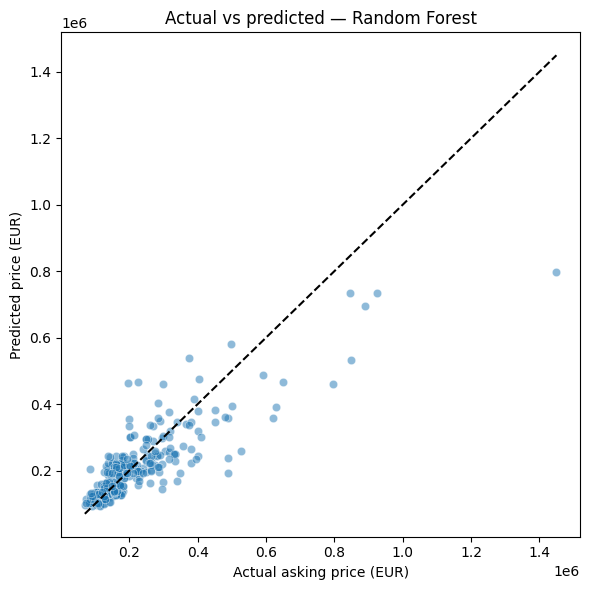

Best model by test MAE: Random Forest
MAE: 51590.05 EUR


In [17]:
best_name = results_df.iloc[0]['Model']
best_pred = predictions[best_name]
plt.figure(figsize=(6,6)); sns.scatterplot(x=y_test, y=best_pred, alpha=.5)
lims = [min(y_test.min(), best_pred.min()), max(y_test.max(), best_pred.max())]
plt.plot(lims, lims, '--', color='black'); plt.xlabel('Actual asking price (EUR)'); plt.ylabel('Predicted price (EUR)'); plt.title('Actual vs predicted — '+best_name); plt.tight_layout(); plt.show()
print('Best model by test MAE:', best_name)
print('MAE:', round(mean_absolute_error(y_test, best_pred),2), 'EUR')

Each dot is one apartment from the test set. The closer the dots are to the diagonal line, the closer the predictions are to the actual asking prices.

## 8. Example prediction (illustrative input)

In [18]:
example = pd.DataFrame([{'povrsina_m2':60, 'sobe':2, 'city_model':'Podgorica'}])
print('Estimated asking price for example apartment: €{:,.0f}'.format(models[best_name].predict(example)[0]))

Estimated asking price for example apartment: €161,119


This is an example prediction for a 60 m² apartment with two rooms in Podgorica. It is an estimate from the model, not a confirmed sale price.

## 9. Conclusion & limitations
After running the notebook, fill in:
- **Sample:** ___ real apartments after cleaning; ___ used for testing.
- **EDA:** Highest median €/m² among sufficiently represented cities: ___.
- **Best model:** ___; **MAE:** ___ EUR; **RMSE:** ___ EUR; **R²:** ___.
- **Limitations:** Listing prices are not final sale prices; missing and inconsistent city information; possible duplicates across websites; limited features; sampling bias; synthetic records excluded from real-world evaluation.
- **Next step:** Collect richer verified listing attributes and time-stamped historical Podgorica price data for a separate 6-month market forecast.

**Academic integrity:** 2,000 generated rows remain labeled in the source dataset. Do not present them as actual scraped listings.